In [1]:
import dtreeviz

In [2]:
import graphviz.backend as be

In [3]:
from sklearn.datasets import *
from dtreeviz.trees import *
from IPython.display import Image, display_svg, SVG

In [6]:
clas = tree.DecisionTreeClassifier()  
iris = load_iris()

X_train = iris.data
y_train = iris.target
clas.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [7]:
# from sklearn.tree import plot_tree
# plot_tree(clas)
import numpy as np
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import plot_tree

import dtreeviz

In [8]:
iris = load_iris()

X = iris.data
y = iris.target

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [10]:
clas = tree.DecisionTreeClassifier()

clas.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


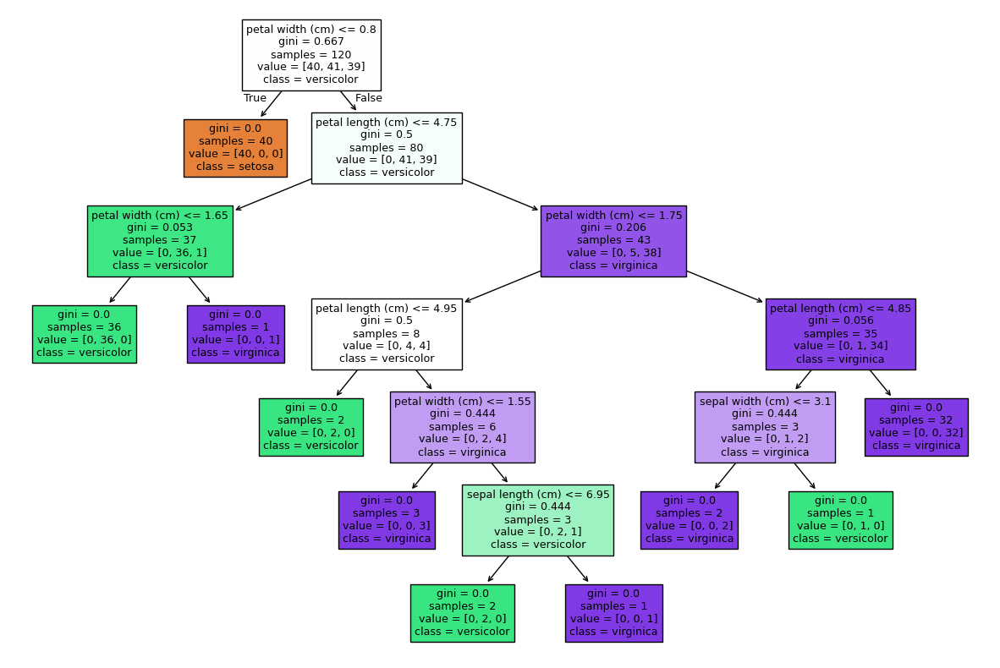

In [11]:
plt.figure(figsize=(15, 10))

plot_tree(
    clas,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True
)

plt.show()

# 1. Classification

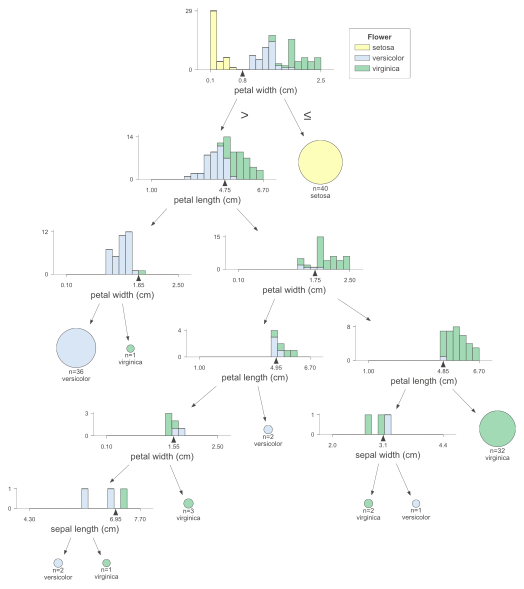

In [15]:
viz = dtreeviz.model(
    clas,
    X_train=X_train,
    y_train=y_train,
    feature_names=iris.feature_names,
    target_name="Flower",
    class_names=list(iris.target_names)
)

viz.view()

# 2. Regression

In [20]:
from sklearn import tree
from sklearn.datasets import fetch_california_housing
import dtreeviz

In [21]:
regr = tree.DecisionTreeRegressor(max_depth=1)

boston = fetch_california_housing()

X_train = boston.data
y_train = boston.target

regr.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [24]:
viz = dtreeviz.model(
    regr,
    X_train=X_train,
    y_train=y_train,
    target_name='price',
    feature_names=boston.feature_names
)

viz.view(scale=2)

# 3. Horizontal Decision Tree

In [28]:
from sklearn.datasets import load_iris
from sklearn import tree
import dtreeviz

iris = load_iris()

X_train = iris.data
y_train = iris.target

In [29]:
clas = tree.DecisionTreeClassifier(max_depth=3)

clas.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [30]:
print("X_train shape:", X_train.shape)
print("Model features:", clas.n_features_in_)

X_train shape: (150, 4)
Model features: 4


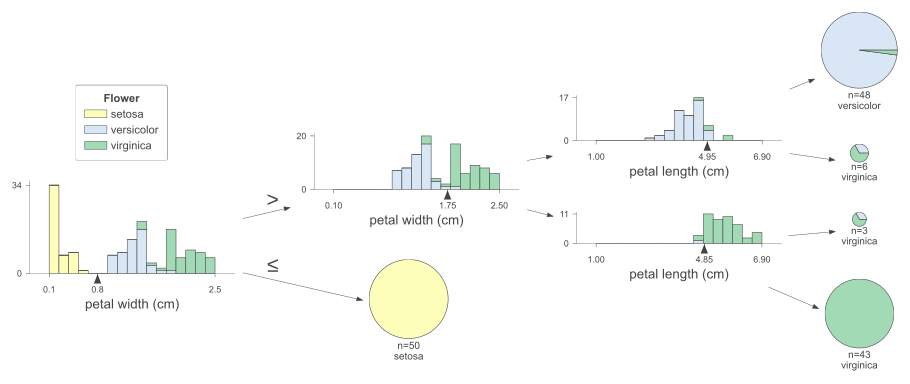

In [31]:
viz = dtreeviz.model(
    clas,
    X_train=X_train,
    y_train=y_train,
    target_name='Flower',
    feature_names=iris.feature_names,
    class_names=list(iris.target_names)
)

viz.view(scale=1.5, orientation='LR')

# 4. Show prediction path

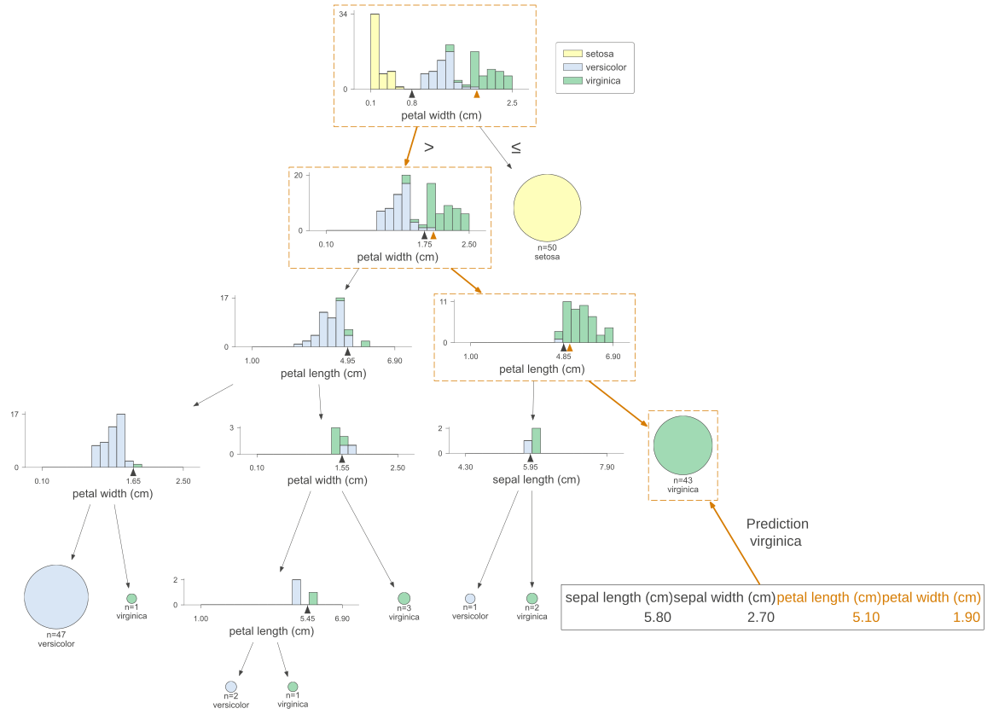

In [33]:
viz = dtreeviz.model(
    clas,
    X_train=X_train,
    y_train=y_train,
    feature_names=iris.feature_names,
    class_names=list(iris.target_names)
)

viz.view(
    x=X,
    scale=1.5
)

In [34]:
X

array([5.8, 2.7, 5.1, 1.9])

# 5. Show node number

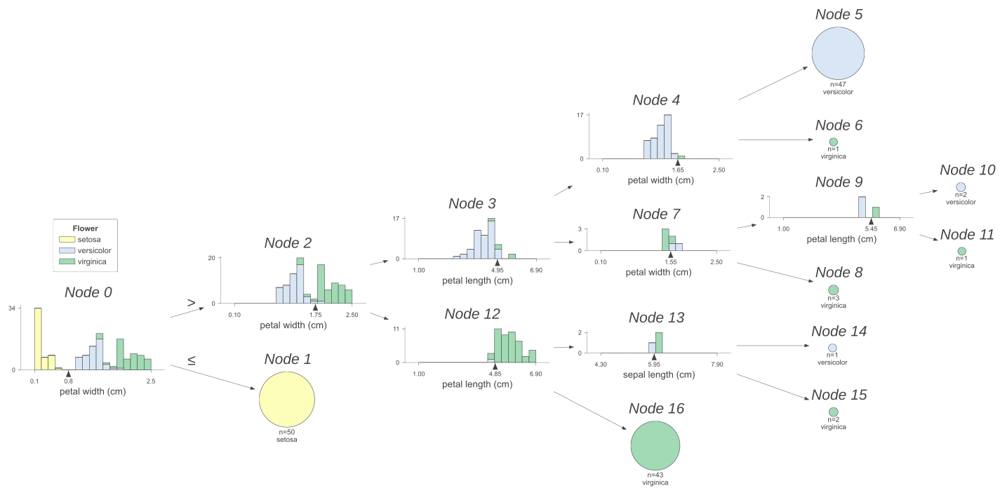

In [36]:
viz = dtreeviz.model(
    clas,
    X_train=X_train,
    y_train=y_train,
    target_name='Flower',
    feature_names=iris.feature_names,
    class_names=['setosa', 'versicolor', 'virginica']
)

viz.view(
    histtype='barstacked',
    scale=1.5,
    orientation='LR',
    show_node_labels=True
)

# 6. Without Any graphs

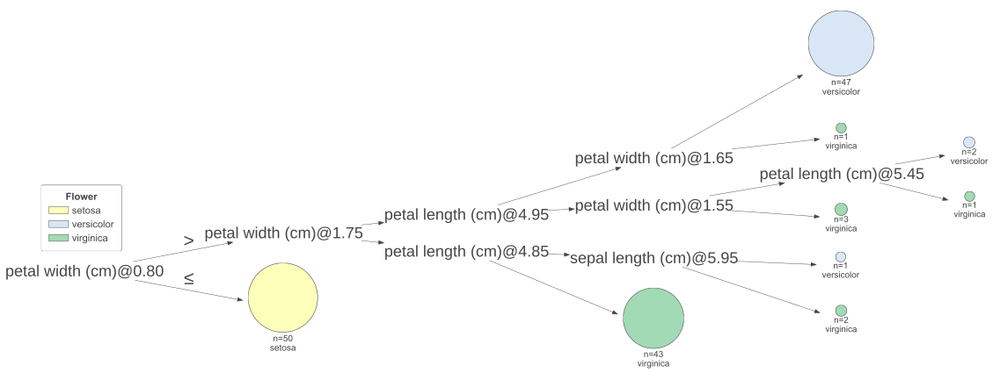

In [38]:
viz = dtreeviz.model(
    clas,
    X_train=X_train,
    y_train=y_train,
    target_name='Flower',
    feature_names=iris.feature_names,
    class_names=['setosa', 'versicolor', 'virginica']
)

viz.view(
    histtype='barstacked',
    scale=1.5,
    orientation='LR',
    fancy=False
)

# 7. Show just prediction path, nothing else

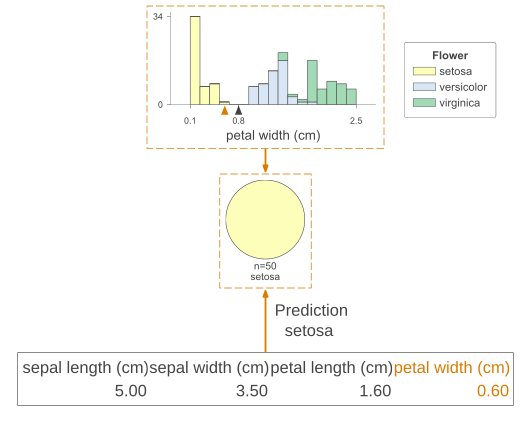

In [40]:
viz = dtreeviz.model(
    clas,
    X_train=X_train,
    y_train=y_train,
    target_name='Flower',
    feature_names=iris.feature_names,
    class_names=list(iris.target_names)
)

viz.view(
    x=X,
    show_just_path=True,
    scale=1.5
)

# 8. Prediction Path in Plain english

In [48]:
viz_model = dtreeviz.model(
    clas,
    X_train=X_train,
    y_train=y_train,
    feature_names=iris.feature_names,
    target_name="Flower",
    class_names=list(iris.target_names)
)

In [53]:
print(viz_model.explain_prediction_path(x=X))
print([m for m in dir(viz_model) if "explain" in m])

petal width (cm) < 0.8

['explain_prediction_path']


# 9. Feature Importance

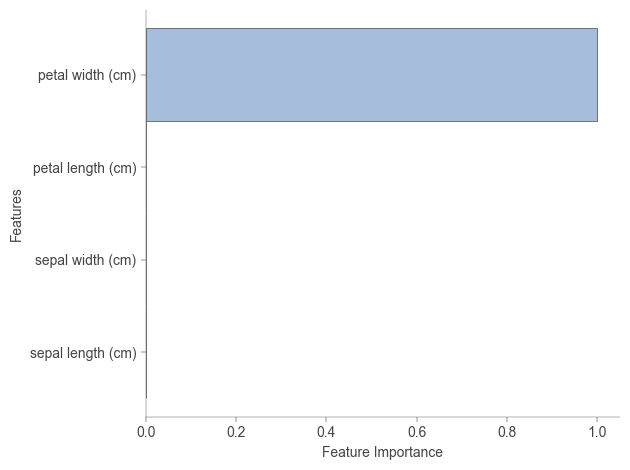

In [54]:
viz_model.instance_feature_importance(x=X)

petal width (cm) < 0.8



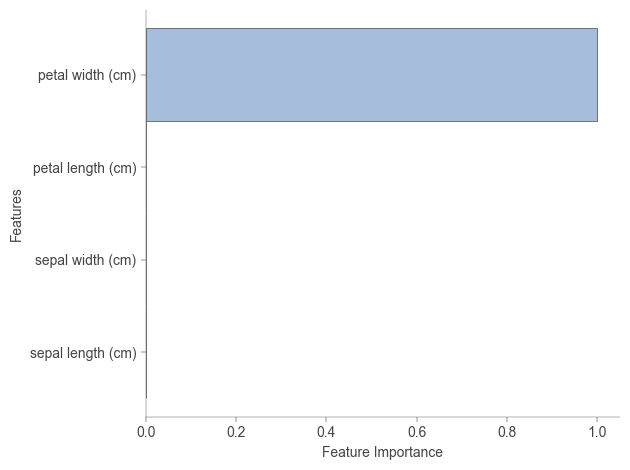

In [55]:
# Text explanation
print(viz_model.explain_prediction_path(x=X))

# Feature importance visualization
viz_model.instance_feature_importance(x=X)

# 10. Univariate Regression

In [60]:
import pandas as pd

df_cars = pd.read_csv("cars.csv")

print(df_cars.head())
print(df_cars.columns.tolist())

   Dimensions.Height  Dimensions.Length  Dimensions.Width  \
0                140                143               202   
1                140                143               202   
2                140                143               202   
3                140                143               202   
4                140                143               202   

  Engine Information.Driveline                Engine Information.Engine Type  \
0              All-wheel drive          Audi 3.2L 6 cylinder 250hp 236ft-lbs   
1            Front-wheel drive  Audi 2.0L 4 cylinder 200 hp 207 ft-lbs Turbo   
2            Front-wheel drive  Audi 2.0L 4 cylinder 200 hp 207 ft-lbs Turbo   
3              All-wheel drive  Audi 2.0L 4 cylinder 200 hp 207 ft-lbs Turbo   
4              All-wheel drive  Audi 2.0L 4 cylinder 200 hp 207 ft-lbs Turbo   

   Engine Information.Hybrid  Engine Information.Number of Forward Gears  \
0                       True                                           6   


In [61]:
print(df_cars.columns.tolist())

['Dimensions.Height', 'Dimensions.Length', 'Dimensions.Width', 'Engine Information.Driveline', 'Engine Information.Engine Type', 'Engine Information.Hybrid', 'Engine Information.Number of Forward Gears', 'Engine Information.Transmission', 'Fuel Information.City mpg', 'Fuel Information.Fuel Type', 'Fuel Information.Highway mpg', 'Identification.Classification', 'Identification.ID', 'Identification.Make', 'Identification.Model Year', 'Identification.Year', 'Engine Information.Engine Statistics.Horsepower', 'Engine Information.Engine Statistics.Torque']


In [64]:
viz_model = dtreeviz.model(
    dt,
    X_train=X,
    y_train=y,
    feature_names=['Vehicle Width', 'Vehicle Length'],
    target_name='City MPG'
)

viz_model.view()

c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names


NameError: name 'rtreeviz_univar' is not defined

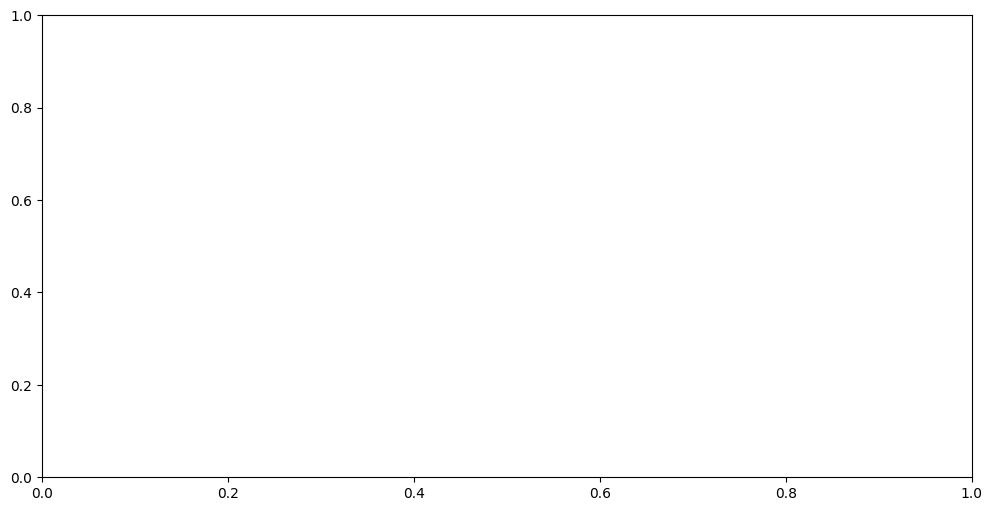

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from dtreeviz.trees import *

# Load dataset
df_cars = pd.read_csv("cars.csv")

# Select input and output
X = df_cars[['Dimensions.Width']]
y = df_cars['Fuel Information.City mpg']

# Train Decision Tree Regressor
dt = DecisionTreeRegressor(
    max_depth=3,
    criterion="absolute_error"
)

dt.fit(X, y)

# Visualize regression tree
fig, ax = plt.subplots(figsize=(12, 6))

rtreeviz_univar(
    dt,
    X,
    y,
    feature_name='Dimensions.Width',
    target_name='City MPG',
    ax=ax
)

plt.show()

# 11. 3-D Regression 

In [40]:
df_cars = pd.read_csv("cars.csv")

df_cars

,MPG,CYL,ENG,WGT
0,18.0,8,307.0,3504
1,15.0,8,350.0,3693
2,18.0,8,318.0,3436
3,16.0,8,304.0,3433
4,17.0,8,302.0,3449
...,...,...,...,...
387,27.0,4,140.0,2790
388,44.0,4,97.0,2130
389,32.0,4,135.0,2295
390,28.0,4,120.0,2625


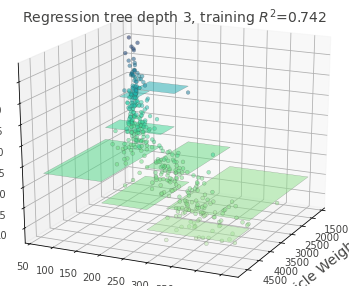

In [41]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.tree import DecisionTreeRegressor
from dtreeviz.trees import *


X = df_cars[['WGT','ENG']]
y = df_cars['MPG']

dt = DecisionTreeRegressor(max_depth=3, criterion="mae")
dt.fit(X, y)

figsize = (6,5)
fig = plt.figure(figsize=figsize)
ax = fig.add_subplot(111, projection='3d')

t = rtreeviz_bivar_3D(dt,
                      X, y,
                      feature_names=['Vehicle Weight', 'Horse Power'],
                      target_name='MPG',
                      fontsize=14,
                      elev=20,
                      azim=25,
                      dist=8.2,
                      show={'splits','title'},
                      ax=ax)
plt.show()

In [ ]:
git add .
git commit -m ""